In [3]:
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

RAW = ROOT / "data" / "raw"
INTERIM = ROOT / "data" / "interim"
PROCESSED = ROOT / "data" / "processed"

print("Arquivos encontrados:")
for arquivo in RAW.iterdir():
    print(arquivo.name)


Arquivos encontrados:
dicionario_PNS_microdados_2019.xlsx
PNS_2019.txt


In [4]:
txt_path = RAW / "PNS_2019.txt"

with open(txt_path, "r", encoding="latin-1") as arquivo:
    for i in range(3):
        linha = arquivo.readline()

        print(f"Registro {i + 1}:")
        print(repr(linha[:120]))
        print("Comprimento:", len(linha.rstrip("\r\n")))
        print()


Registro 1:
'111110011110000016000101201906111 111105021 1102   411011011012  1012  2  2  2  12  100020000  0014450601012221119630551'
Comprimento: 1548

Registro 2:
'111110011110000016000101201906110 111105021 1102   411011011012  1012  2  2  2  12  100020000  0014450602021080419500694'
Comprimento: 1548

Registro 3:
'111110011110000016000101201906110 111105021 1102   411011011012  1012  2  2  2  12  100020000  0014450603061130919870312'
Comprimento: 1548



In [5]:
# Variáveis de entrada (X)
variaveis_x = {
    "V0001": (1, 2),  # UF
    "V0026": (31, 1),  # Urbana/Rural
    "C006": (108, 1),  # Sexo
    "C008": (117, 3),  # Idade
    "C009": (120, 1),  # Raça/cor
    "C011": (133, 1),  # Estado civil
    "V0022": (29, 2),  # Número de moradores
    "VDD004A": (1514, 1),  # Escolaridade
    "VDE002": (1516, 1),  # Situação de trabalho
    "VDF003": (1527, 8),  # Renda per capita
}

# Variáveis usadas para construir o Y
variaveis_y = {
    "P034": (673, 1),
    "P035": (674, 1),
    "P03701": (675, 2),
    "P03702": (677, 2),
    "P036": (679, 2),
}

variaveis = {**variaveis_x, **variaveis_y}

print(f"Total de variáveis: {len(variaveis)}")


Total de variáveis: 15


In [6]:
registros = []

with open(txt_path, "r", encoding="latin-1") as arquivo:
    for i, linha in enumerate(arquivo):

        if i >= 10:
            break

        registro = {}

        for nome, (inicio, tamanho) in variaveis.items():
            # O dicionário começa em 1; Python começa em 0
            posicao = inicio - 1

            valor = linha[posicao : posicao + tamanho].strip()

            registro[nome] = valor if valor else None

        registros.append(registro)

df_teste = pd.DataFrame(registros)

display(df_teste)


,V0001,V0026,C006,C008,C009,C011,V0022,VDD004A,VDE002,VDF003,P034,P035,P03701,P03702,P036
0,11,1,2,055,1,1,06,2,1,00000350,1,1,00,30,01
1,11,1,1,069,4,1,06,1,NaN,00000350,NaN,NaN,NaN,NaN,NaN
2,11,1,1,031,2,4,06,5,1,00000350,NaN,NaN,NaN,NaN,NaN
3,11,1,1,009,2,NaN,06,1,NaN,00000350,NaN,NaN,NaN,NaN,NaN
4,11,1,2,006,4,NaN,06,1,NaN,00000350,NaN,NaN,NaN,NaN,NaN
5,11,1,2,004,2,NaN,06,NaN,NaN,00000350,NaN,NaN,NaN,NaN,NaN
6,11,1,2,033,1,4,04,2,1,00000250,NaN,NaN,NaN,NaN,NaN
7,11,1,1,017,1,4,04,4,NaN,00000250,NaN,NaN,NaN,NaN,NaN
8,11,1,2,015,4,4,04,3,NaN,00000250,NaN,NaN,NaN,NaN,NaN
9,11,1,2,019,4,4,04,4,1,00000250,2,NaN,NaN,NaN,NaN


In [7]:
# Extrair todas as linhas do TXT
registros = []
linhas_invalidas = 0

with open(txt_path, "r", encoding="latin-1") as arquivo:
    for linha in arquivo:

        linha = linha.rstrip("\r\n")

        if len(linha) != 1548:
            linhas_invalidas += 1
            continue

        registro = {}

        for nome, (inicio, tamanho) in variaveis.items():
            posicao = inicio - 1
            valor = linha[posicao : posicao + tamanho].strip()
            registro[nome] = valor if valor else None

        registros.append(registro)

df = pd.DataFrame(registros)

print("Quantidade de registros:", len(df))
print("Quantidade de colunas:", len(df.columns))
print("Linhas com tamanho inesperado:", linhas_invalidas)

display(df.head())


Quantidade de registros: 293726
Quantidade de colunas: 15
Linhas com tamanho inesperado: 0


,V0001,V0026,C006,C008,C009,C011,V0022,VDD004A,VDE002,VDF003,P034,P035,P03701,P03702,P036
0,11,1,2,055,1,1,06,2,1,00000350,1,1,00,30,01
1,11,1,1,069,4,1,06,1,NaN,00000350,NaN,NaN,NaN,NaN,NaN
2,11,1,1,031,2,4,06,5,1,00000350,NaN,NaN,NaN,NaN,NaN
3,11,1,1,009,2,NaN,06,1,NaN,00000350,NaN,NaN,NaN,NaN,NaN
4,11,1,2,006,4,NaN,06,1,NaN,00000350,NaN,NaN,NaN,NaN,NaN


In [8]:
INTERIM.mkdir(parents=True, exist_ok=True)

caminho_parquet = INTERIM / "pns_extraida.parquet"

df.to_parquet(caminho_parquet, engine="pyarrow", index=False)

print("Base salva em:", caminho_parquet)


Base salva em: /home/jean/pns-atividade-fisica-knn/data/interim/pns_extraida.parquet


In [9]:
amostra = df.sample(n=min(1000, len(df)), random_state=42)

caminho_csv = INTERIM / "pns_amostra.csv"

amostra.to_csv(caminho_csv, index=False, sep=";", encoding="utf-8-sig")

print("Amostra salva em:", caminho_csv)


Amostra salva em: /home/jean/pns-atividade-fisica-knn/data/interim/pns_amostra.csv


In [10]:
print("Dimensões da base:", df.shape)

display(df.isna().sum().to_frame("Quantidade de ausentes"))

print("\nDistribuição de P034:")
display(df["P034"].value_counts(dropna=False))

print("\nDistribuição das idades:")
display(df["C008"].value_counts(dropna=False).head(20))


Dimensões da base: (293726, 15)


,Quantidade de ausentes
V0001,0
V0026,0
C006,14344
C008,14344
C009,14344
C011,51282
V0022,14344
VDD004A,32131
VDE002,157131
VDF003,14516



Distribuição de P034:


P034
NaN    202880
2       54448
1       36398
Name: count, dtype: int64


Distribuição das idades:


C008
NaN    14344
018     4667
019     4508
014     4468
037     4460
015     4454
017     4432
022     4375
016     4364
036     4329
013     4294
040     4287
020     4272
021     4266
039     4264
023     4255
012     4252
010     4248
038     4244
024     4234
Name: count, dtype: int64

In [11]:
colunas_y = ["P034", "P035", "P03701", "P03702", "P036"]

# Quantidade de campos preenchidos segundo P034
diagnostico = df.groupby("P034", dropna=False)[colunas_y[1:]].count()

display(diagnostico)


,P035,P03701,P03702,P036
P034,,,,
1,36398,35196,35196,35196
2,0,0,0,0
NaN,0,0,0,0


In [12]:
praticantes = df[df["P034"] == "1"].copy()

incompletos = praticantes[
    praticantes[["P035", "P03701", "P03702", "P036"]].isna().any(axis=1)
]

print("Pessoas que declararam praticar:", len(praticantes))
print("Registros com alguma informação ausente:", len(incompletos))

display(incompletos.head(15))


Pessoas que declararam praticar: 36398
Registros com alguma informação ausente: 1202


,V0001,V0026,C006,C008,C009,C011,V0022,VDD004A,VDE002,VDF003,P034,P035,P03701,P03702,P036
32,11,1,2,052,4,4,02,2,1,00000125,1,0,NaN,NaN,NaN
200,11,1,1,061,1,1,04,7,1,00002625,1,0,NaN,NaN,NaN
222,11,1,1,022,4,4,02,6,NaN,00000850,1,0,NaN,NaN,NaN
255,11,1,2,034,1,1,06,4,NaN,00000500,1,0,NaN,NaN,NaN
299,11,1,2,027,4,4,06,6,2,00000867,1,0,NaN,NaN,NaN
912,11,1,1,066,2,1,02,5,1,00004175,1,0,NaN,NaN,NaN
1111,11,1,2,035,1,2,04,5,1,00001263,1,0,NaN,NaN,NaN
1133,11,1,2,045,4,1,04,5,1,00001470,1,0,NaN,NaN,NaN
1255,11,1,2,036,4,4,04,5,1,00000913,1,0,NaN,NaN,NaN
1259,11,1,1,018,4,4,04,5,1,00000568,1,0,NaN,NaN,NaN


In [13]:
# Verificar as frequências dos códigos nas respostas
for coluna in colunas_y:
    print(f"\n{coluna}")
    display(df[coluna].value_counts(dropna=False).head(25))



P034


P034
NaN    202880
2       54448
1       36398
Name: count, dtype: int64


P035


P035
NaN    257328
3        8376
2        6750
5        6336
1        5610
7        3639
4        2904
6        1581
0        1202
Name: count, dtype: int64


P03701


P03701
NaN    258530
01      20300
00       8368
02       5091
03        996
04        289
05         69
06         37
08         25
07          9
10          8
15          2
14          1
12          1
Name: count, dtype: int64


P03702


P03702
NaN    258530
00      20021
30       8566
40       2795
20       1079
45        817
50        810
15        488
10        338
25         85
35         69
05         32
59         24
55         15
01          9
03          8
12          7
06          4
42          4
04          4
08          3
48          2
38          2
02          2
44          2
Name: count, dtype: int64


P036


P036
NaN    258530
01      13204
12       6271
05       5769
03       1678
11       1528
06       1484
08       1311
17        820
16        625
02        620
07        483
10        481
14        337
09        267
04        177
13         75
15         66
Name: count, dtype: int64

In [14]:
# Selecionar quem pratica pelo menos uma vez por semana
df_ativos = df[
    (df["P034"] == "1")
    & (df["P035"].isin(["1", "2", "3", "4", "5", "6", "7"]))
].copy()

# Converter as respostas para números
df_ativos["dias"] = pd.to_numeric(df_ativos["P035"])
df_ativos["horas"] = pd.to_numeric(df_ativos["P03701"])
df_ativos["minutos"] = pd.to_numeric(df_ativos["P03702"])

# Calcular minutos semanais
df_ativos["minutos_semanais"] = df_ativos["dias"] * (
    df_ativos["horas"] * 60 + df_ativos["minutos"]
)

print("Praticantes regulares:", len(df_ativos))

display(
    df_ativos[
        [
            "P034",
            "P035",
            "P036",
            "dias",
            "horas",
            "minutos",
            "minutos_semanais",
        ]
    ].head(15)
)


Praticantes regulares: 35196


,P034,P035,P036,dias,horas,minutos,minutos_semanais
0,1,1,01,1,0,30,30
18,1,3,01,3,1,0,180
19,1,1,01,1,0,30,30
22,1,7,05,7,2,0,840
29,1,7,10,7,2,0,840
34,1,2,01,2,1,0,120
35,1,2,01,2,1,0,120
41,1,7,06,7,3,0,1260
44,1,2,03,2,0,30,60
51,1,3,04,3,1,30,270


In [15]:
display(df_ativos["minutos_semanais"].describe())

print("\nFrequência das modalidades:")
display(df_ativos["P036"].value_counts())


count    35196.000000
mean       255.827367
std        221.952286
min          1.000000
25%        120.000000
50%        180.000000
75%        300.000000
max       6300.000000
Name: minutos_semanais, dtype: float64


Frequência das modalidades:


P036
01    13204
12     6271
05     5769
03     1678
11     1528
06     1484
08     1311
17      820
16      625
02      620
07      483
10      481
14      337
09      267
04      177
13       75
15       66
Name: count, dtype: int64

In [16]:
# Identificar os 20 maiores tempos semanais
extremos = df_ativos.nlargest(20, "minutos_semanais")

display(
    extremos[
        [
            "C008",
            "C006",
            "P035",
            "P03701",
            "P03702",
            "P036",
            "minutos_semanais",
        ]
    ]
)


,C008,C006,P035,P03701,P03702,P036,minutos_semanais
131582,036,2,7,15,00,06,6300
146364,015,2,7,14,00,05,5880
187963,027,1,7,10,00,11,4200
19526,038,1,7,08,00,12,3360
119517,076,1,7,08,00,01,3360
231916,033,1,7,08,00,01,3360
272016,047,1,7,08,00,12,3360
148798,019,2,5,10,45,05,3225
223162,034,1,5,10,00,01,3000
101870,046,2,6,08,15,06,2970


In [17]:
q1 = df_ativos["minutos_semanais"].quantile(0.25)
q3 = df_ativos["minutos_semanais"].quantile(0.75)

iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr

outliers = df_ativos[df_ativos["minutos_semanais"] > limite_superior]

print("Limite superior:", limite_superior)
print("Quantidade de possíveis outliers:", len(outliers))
print("Percentual:", round(len(outliers) / len(df_ativos) * 100, 2), "%")


Limite superior: 570.0
Quantidade de possíveis outliers: 2695
Percentual: 7.66 %


In [19]:
# Criar uma coluna que identifica possíveis outliers
df_ativos["outlier_tempo"] = df_ativos["minutos_semanais"] > limite_superior

# Contagem por categoria
print("Distribuição dos registros:")
display(df_ativos["outlier_tempo"].value_counts())

# Resumo estatístico
display(
    df_ativos.groupby("outlier_tempo")["minutos_semanais"].agg(
        ["count", "min", "median", "mean", "max"]
    )
)


Distribuição dos registros:


outlier_tempo
False    32501
True      2695
Name: count, dtype: int64

,count,min,median,mean,max
outlier_tempo,,,,,
False,32501,1,180.0,210.074890,560
True,2695,595,720.0,807.590353,6300


In [20]:
# Duração diária total em minutos
df_ativos["minutos_diarios"] = df_ativos["horas"] * 60 + df_ativos["minutos"]

# Marcar durações superiores a 8 horas por dia
df_ativos["tempo_diario_extremo"] = df_ativos["minutos_diarios"] > 480

print("Registros com mais de 8 horas por dia:")
print(df_ativos["tempo_diario_extremo"].sum())

display(
    df_ativos.loc[
        df_ativos["tempo_diario_extremo"],
        [
            "C008",
            "C006",
            "P035",
            "P036",
            "minutos_diarios",
            "minutos_semanais",
        ],
    ]
    .sort_values("minutos_diarios", ascending=False)
    .head(20)
)


Registros com mais de 8 horas por dia:
14


,C008,C006,P035,P036,minutos_diarios,minutos_semanais
1420,020,2,2,06,930,1860
131582,036,2,7,06,900,6300
146364,015,2,7,05,840,5880
255569,030,1,1,17,720,720
148798,019,2,5,05,645,3225
243261,030,1,3,11,630,1890
223162,034,1,5,01,600,3000
187963,027,1,7,11,600,4200
137486,050,2,3,01,600,1800
170940,019,1,2,12,600,1200


In [21]:
resumo_outliers = pd.DataFrame(
    {
        "Critério": [
            "IQR (> 570 min/semana)",
            "Mais de 8 horas/dia",
            "Ambos os critérios",
        ],
        "Quantidade": [
            df_ativos["outlier_tempo"].sum(),
            df_ativos["tempo_diario_extremo"].sum(),
            (
                df_ativos["outlier_tempo"] & df_ativos["tempo_diario_extremo"]
            ).sum(),
        ],
    }
)

resumo_outliers["Percentual (%)"] = (
    resumo_outliers["Quantidade"] / len(df_ativos) * 100
).round(2)

display(resumo_outliers)


,Critério,Quantidade,Percentual (%)
0,IQR (> 570 min/semana),2695,7.66
1,Mais de 8 horas/dia,14,0.04
2,Ambos os critérios,14,0.04


In [22]:
# Selecionar registros sinalizados por pelo menos um critério
df_suspeitos = df_ativos[
    df_ativos["outlier_tempo"] | df_ativos["tempo_diario_extremo"]
].copy()

# Salvar diagnóstico sem alterar a base original
df_suspeitos.to_parquet(INTERIM / "pns_outliers_tempo.parquet", index=True)

print("Registros sinalizados:", len(df_suspeitos))
print("Diagnóstico salvo com sucesso!")


Registros sinalizados: 2695
Diagnóstico salvo com sucesso!


In [23]:
limites = [4, 6, 8]

for horas in limites:
    quantidade = (df_ativos["minutos_diarios"] > horas * 60).sum()
    percentual = quantidade / len(df_ativos) * 100

    print(
        f"Mais de {horas}h/dia: " f"{quantidade} registros ({percentual:.2f}%)"
    )


Mais de 4h/dia: 156 registros (0.44%)
Mais de 6h/dia: 48 registros (0.14%)
Mais de 8h/dia: 14 registros (0.04%)


In [24]:
# Índices dos registros com mais de 6 horas diárias
indices_outliers = df_ativos.index[df_ativos["minutos_diarios"] > 360]

# Criar uma nova base excluindo esses registros
df_limpo = df.drop(index=indices_outliers).copy()

print("Registros originais:", len(df))
print("Outliers removidos:", len(indices_outliers))
print("Registros restantes:", len(df_limpo))


Registros originais: 293726
Outliers removidos: 48
Registros restantes: 293678


In [25]:
# Manter entrevistados com resposta válida
df_limpo = df_limpo[df_limpo["P034"].isin(["1", "2"])].copy()

print("Registros após filtragem:", len(df_limpo))


Registros após filtragem: 90798


In [26]:
# Variáveis numéricas
numericas = ["C008", "V0022", "VDF003"]

for coluna in numericas:
    df_limpo[coluna] = pd.to_numeric(df_limpo[coluna], errors="coerce")

# Variáveis categóricas
categoricas = ["V0001", "V0026", "C006", "C009", "C011", "VDD004A", "VDE002"]

# Converter códigos ignorados apenas onde são
# códigos especiais confirmados, sem alterar códigos válidos.
df_limpo["C009"] = df_limpo["C009"].replace("9", pd.NA)
df_limpo["C011"] = df_limpo["C011"].replace("9", pd.NA)

print(df_limpo[numericas].dtypes)
display(df_limpo[numericas].describe())


C008        int64
V0022       int64
VDF003    float64
dtype: object


,C008,V0022,VDF003
count,90798.000000,90798.000000,90776.000000
mean,46.398610,2.945527,1595.710386
std,17.595949,1.508359,2816.146264
min,15.000000,1.000000,0.000000
25%,32.000000,2.000000,499.000000
50%,45.000000,3.000000,998.000000
75%,60.000000,4.000000,1665.000000
max,107.000000,23.000000,203196.000000


In [27]:
# Garantir que as respostas de frequência sejam válidas
frequencias_validas = [str(i) for i in range(8)]

# Remover respostas inconsistentes dos praticantes
inconsistentes = (df_limpo["P034"] == "1") & (
    ~df_limpo["P035"].isin(frequencias_validas)
)

print("Inconsistências na frequência:", inconsistentes.sum())

df_limpo = df_limpo.loc[~inconsistentes].copy()

# Converter campos de duração
for coluna in ["P035", "P03701", "P03702"]:
    df_limpo[coluna] = pd.to_numeric(df_limpo[coluna], errors="coerce")

# Calcular tempo semanal para quem possui informações
df_limpo["minutos_semanais"] = df_limpo["P035"] * (
    60 * df_limpo["P03701"] + df_limpo["P03702"]
)

# Não praticantes recebem 0 minutos
df_limpo.loc[df_limpo["P034"] == "2", "minutos_semanais"] = 0

# Frequência inferior a uma vez por semana
df_limpo.loc[
    (df_limpo["P034"] == "1") & (df_limpo["P035"] == 0), "minutos_semanais"
] = 0


Inconsistências na frequência: 0


In [28]:
# Salvar versão intermediária limpa
caminho = INTERIM / "pns_limpa_pre_y.parquet"

df_limpo.to_parquet(caminho, index=False)

# Criar amostra para visualização
df_limpo.head(1000).to_csv(
    INTERIM / "pns_limpa_amostra.csv",
    sep=";",
    index=False,
    encoding="utf-8-sig",
)

print("Dimensões da base limpa:", df_limpo.shape)
print("Arquivo salvo:", caminho)


Dimensões da base limpa: (90798, 16)
Arquivo salvo: /home/jean/pns-atividade-fisica-knn/data/interim/pns_limpa_pre_y.parquet


In [29]:
# Recuperar VDE001 do TXT original

valores = []

with open(txt_path, "r", encoding="latin-1") as arquivo:
    for linha in arquivo:
        if len(linha.rstrip("\r\n")) != 1548:
            continue

        valor = linha[1514:1515].strip()
        valores.append(valor if valor else None)

# Adicionar à base original
assert len(valores) == len(df)

df["VDE001"] = valores

print("Distribuição de VDE001:")
display(df["VDE001"].value_counts(dropna=False))


Distribuição de VDE001:


VDE001
1      136595
2       88968
NaN     68163
Name: count, dtype: int64

In [30]:
# Recriar a base mantendo nossas decisões de limpeza

indices_outliers = df_ativos.index[df_ativos["minutos_diarios"] > 360]

df_tratado = df.drop(index=indices_outliers).copy()

df_tratado = df_tratado[df_tratado["P034"].isin(["1", "2"])].copy()

print("Registros:", len(df_tratado))


Registros: 90798


In [31]:
condicoes = [
    (df_tratado["VDE001"] == "1") & (df_tratado["VDE002"] == "1"),
    (df_tratado["VDE001"] == "1") & (df_tratado["VDE002"] == "2"),
    (df_tratado["VDE001"] == "2") & (df_tratado["VDE002"].isna()),
]

categorias = ["Ocupado", "Desocupado", "Fora da força de trabalho"]

df_tratado["situacao_trabalho"] = np.select(
    condicoes, categorias, default="Verificar"
)

display(df_tratado["situacao_trabalho"].value_counts())


situacao_trabalho
Ocupado                      52808
Fora da força de trabalho    34083
Desocupado                    3907
Name: count, dtype: int64

In [32]:
variaveis_x = [
    "C008",
    "C006",
    "VDD004A",
    "VDF003",
    "V0001",
    "V0026",
    "C009",
    "C011",
    "V0022",
]

resumo = pd.DataFrame(
    {
        "Ausentes": df_tratado[variaveis_x].isna().sum(),
        "Percentual (%)": (df_tratado[variaveis_x].isna().mean() * 100).round(
            2
        ),
    }
)

display(resumo)

print("Situações de trabalho a verificar:")
print((df_tratado["situacao_trabalho"] == "Verificar").sum())


,Ausentes,Percentual (%)
C008,0,0.00
C006,0,0.00
VDD004A,0,0.00
VDF003,22,0.02
V0001,0,0.00
V0026,0,0.00
C009,0,0.00
C011,0,0.00
V0022,0,0.00


Situações de trabalho a verificar:
0


In [33]:
# Preservar versão anterior ao tratamento de ausentes
df_pre_ausentes = df_tratado.copy()

# Remover registros com renda ausente
df_tratado = df_tratado.dropna(subset=["VDF003"]).copy()

# Verificar resultado
print("Registros antes:", len(df_pre_ausentes))
print("Registros depois:", len(df_tratado))
print("Registros removidos:", len(df_pre_ausentes) - len(df_tratado))

# Confirmar ausência de valores faltantes nas variáveis X
variaveis_finais_x = [
    "C008",
    "C006",
    "VDD004A",
    "VDF003",
    "V0001",
    "V0026",
    "C009",
    "C011",
    "V0022",
    "situacao_trabalho",
]

display(df_tratado[variaveis_finais_x].isna().sum())


Registros antes: 90798
Registros depois: 90776
Registros removidos: 22


C008                 0
C006                 0
VDD004A              0
VDF003               0
V0001                0
V0026                0
C009                 0
C011                 0
V0022                0
situacao_trabalho    0
dtype: int64

In [34]:
categoricas = [
    "C006",  # Sexo
    "C009",  # Raça/cor
    "C011",  # Estado civil
    "VDD004A",  # Escolaridade
    "V0026",  # Urbana/rural
    "situacao_trabalho",
]

for coluna in categoricas:
    print(f"\nVariável: {coluna}")
    display(df_tratado[coluna].value_counts(dropna=False))



Variável: C006


C006
2    48014
1    42762
Name: count, dtype: int64


Variável: C009


C009
4    45957
1    33111
2    10335
5      683
3      680
9       10
Name: count, dtype: int64


Variável: C011


...

VDD004A
2    28602
5    23449
7    13607
1     7656
3     7160
4     6345
6     3957
Name: count, dtype: int64


Variável: V0026


V0026
1    69809
2    20967
Name: count, dtype: int64


Variável: situacao_trabalho


situacao_trabalho
Ocupado                      52787
Fora da força de trabalho    34082
Desocupado                    3907
Name: count, dtype: int64

In [35]:
df_visual = df_tratado.copy()

df_visual = df_visual.rename(
    columns={
        "C008": "idade",
        "C006": "sexo",
        "VDD004A": "escolaridade",
        "VDF003": "renda_per_capita",
        "V0001": "uf",
        "V0026": "area_residencia",
        "C009": "raca_cor",
        "C011": "estado_civil",
        "V0022": "numero_moradores",
    }
)


In [36]:
mapa_sexo = {"1": "Homem", "2": "Mulher"}

mapa_area = {"1": "Urbana", "2": "Rural"}

mapa_escolaridade = {
    "1": "Sem instrução",
    "2": "Fundamental incompleto",
    "3": "Fundamental completo",
    "4": "Médio incompleto",
    "5": "Médio completo",
    "6": "Superior incompleto",
    "7": "Superior completo",
}

mapa_raca = {
    "1": "Branca",
    "2": "Preta",
    "3": "Amarela",
    "4": "Parda",
    "5": "Indígena",
}

mapa_estado_civil = {
    "1": "Casado(a)",
    "2": "Divorciado(a) ou separado(a)",
    "3": "Viúvo(a)",
    "4": "Solteiro(a)",
}

df_visual["sexo"] = df_visual["sexo"].map(mapa_sexo)
df_visual["area_residencia"] = df_visual["area_residencia"].map(mapa_area)
df_visual["escolaridade"] = df_visual["escolaridade"].map(mapa_escolaridade)
df_visual["raca_cor"] = df_visual["raca_cor"].map(mapa_raca)
df_visual["estado_civil"] = df_visual["estado_civil"].map(mapa_estado_civil)


In [37]:
colunas_visualizacao = [
    "idade",
    "sexo",
    "escolaridade",
    "renda_per_capita",
    "uf",
    "situacao_trabalho",
    "area_residencia",
    "raca_cor",
    "estado_civil",
    "numero_moradores",
]

display(df_visual[colunas_visualizacao].head(15))


,idade,sexo,escolaridade,renda_per_capita,uf,situacao_trabalho,area_residencia,raca_cor,estado_civil,numero_moradores
0,055,Mulher,Fundamental incompleto,00000350,11,Ocupado,Urbana,Branca,Casado(a),06
9,019,Mulher,Médio incompleto,00000250,11,Ocupado,Urbana,Parda,Solteiro(a),04
10,045,Mulher,Médio completo,00000500,11,Ocupado,Urbana,Preta,Solteiro(a),08
18,058,Mulher,Sem instrução,00000324,11,Ocupado,Urbana,Preta,Viúvo(a),01
19,028,Mulher,Superior incompleto,00000000,11,Fora da força de trabalho,Urbana,Parda,Solteiro(a),02
21,081,Homem,Fundamental incompleto,00000998,11,Fora da força de trabalho,Urbana,Parda,Solteiro(a),01
22,041,Mulher,Médio completo,00000999,11,Ocupado,Urbana,Parda,Casado(a),03
26,038,Mulher,Médio completo,00000250,11,Fora da força de trabalho,Urbana,Branca,Solteiro(a),04
29,033,Homem,Médio incompleto,00000700,11,Ocupado,Urbana,Parda,Solteiro(a),02
31,081,Homem,Fundamental incompleto,00001398,11,Fora da força de trabalho,Urbana,Parda,Divorciado(a) ou separado(a),01


In [38]:
resumo_final = pd.DataFrame(
    {
        "Ausentes": df_visual[colunas_visualizacao].isna().sum(),
        "Percentual (%)": (
            df_visual[colunas_visualizacao].isna().mean() * 100
        ).round(2),
    }
)

display(resumo_final)


,Ausentes,Percentual (%)
idade,0,0.00
sexo,0,0.00
escolaridade,0,0.00
renda_per_capita,0,0.00
uf,0,0.00
situacao_trabalho,0,0.00
area_residencia,0,0.00
raca_cor,10,0.01
estado_civil,0,0.00
numero_moradores,0,0.00


In [39]:
# Remover os 10 registros sem raça/cor
df_visual = df_visual.dropna(subset=["raca_cor"]).copy()

print("Registros restantes:", len(df_visual))

# Confirmar ausência de valores faltantes
display(df_visual[colunas_visualizacao].isna().sum())


Registros restantes: 90766


idade                0
sexo                 0
escolaridade         0
renda_per_capita     0
uf                   0
situacao_trabalho    0
area_residencia      0
raca_cor             0
estado_civil         0
numero_moradores     0
dtype: int64

In [40]:
# Trabalhar com a base socioeconômica tratada
df_final = df_visual.copy()

# Criar a variável-alvo inicialmente sem classificação
df_final["ativo_lazer"] = pd.NA

# Quem declarou não praticar exercícios
df_final.loc[df_final["P034"] == "2", "ativo_lazer"] = 0

# Quem pratica menos de uma vez por semana
df_final.loc[
    (df_final["P034"] == "1") & (df_final["P035"] == "0"), "ativo_lazer"
] = 0

print("Distribuição parcial do Y:")
display(df_final["ativo_lazer"].value_counts(dropna=False))


Distribuição parcial do Y:


ativo_lazer
0       55634
<NA>    35132
Name: count, dtype: int64

In [41]:
# Converter os campos necessários
for coluna in ["P035", "P03701", "P03702"]:
    df_final[coluna] = pd.to_numeric(df_final[coluna], errors="coerce")

# Calcular duração semanal
df_final["minutos_semanais"] = df_final["P035"] * (
    60 * df_final["P03701"] + df_final["P03702"]
)

# Quem não pratica ou pratica menos de uma vez por semana
# recebe zero minutos na medida operacional semanal
df_final.loc[
    (df_final["P034"] == "2")
    | ((df_final["P034"] == "1") & (df_final["P035"] == 0)),
    "minutos_semanais",
] = 0

display(
    df_final[["P034", "P035", "P036", "minutos_semanais", "ativo_lazer"]].head(
        15
    )
)


,P034,P035,P036,minutos_semanais,ativo_lazer
0,1,1.0,01,30.0,<NA>
9,2,NaN,NaN,0.0,0
10,2,NaN,NaN,0.0,0
18,1,3.0,01,180.0,<NA>
19,1,1.0,01,30.0,<NA>
21,2,NaN,NaN,0.0,0
22,1,7.0,05,840.0,<NA>
26,2,NaN,NaN,0.0,0
29,1,7.0,10,840.0,<NA>
31,2,NaN,NaN,0.0,0


In [42]:
# Converter os campos necessários
for coluna in ["P035", "P03701", "P03702"]:
    df_final[coluna] = pd.to_numeric(df_final[coluna], errors="coerce")

# Calcular duração semanal
df_final["minutos_semanais"] = df_final["P035"] * (
    60 * df_final["P03701"] + df_final["P03702"]
)

# Quem não pratica ou pratica menos de uma vez por semana
# recebe zero minutos na medida operacional semanal
df_final.loc[
    (df_final["P034"] == "2")
    | ((df_final["P034"] == "1") & (df_final["P035"] == 0)),
    "minutos_semanais",
] = 0

display(
    df_final[["P034", "P035", "P036", "minutos_semanais", "ativo_lazer"]].head(
        15
    )
)


,P034,P035,P036,minutos_semanais,ativo_lazer
0,1,1.0,01,30.0,<NA>
9,2,NaN,NaN,0.0,0
10,2,NaN,NaN,0.0,0
18,1,3.0,01,180.0,<NA>
19,1,1.0,01,30.0,<NA>
21,2,NaN,NaN,0.0,0
22,1,7.0,05,840.0,<NA>
26,2,NaN,NaN,0.0,0
29,1,7.0,10,840.0,<NA>
31,2,NaN,NaN,0.0,0


In [43]:
# Analisar somente os praticantes regulares
regulares = df_final[
    (df_final["P034"] == "1") & (df_final["P035"].between(1, 7))
].copy()

resumo_modalidades = (
    regulares.groupby("P036")
    .agg(
        quantidade=("P036", "size"),
        media_minutos=("minutos_semanais", "mean"),
        mediana_minutos=("minutos_semanais", "median"),
    )
    .sort_index()
)

display(resumo_modalidades)


,quantidade,media_minutos,mediana_minutos
P036,,,
01,13186,227.177992,180.0
02,620,234.153226,180.0
03,1676,276.118735,210.0
04,177,288.000000,240.0
05,5762,346.594238,300.0
06,1481,245.668467,180.0
07,483,181.490683,150.0
08,1309,182.026738,120.0
09,265,242.207547,180.0


In [46]:
# Converter idade para número
df_final["idade"] = pd.to_numeric(df_final["idade"], errors="coerce")

# Selecionar adultos de 18 anos ou mais
df_final = df_final[df_final["idade"] >= 18].copy()

print("Tipo da idade:", df_final["idade"].dtype)
print("Registros restantes:", len(df_final))

# Garantir que as variáveis de tempo sejam numéricas
for coluna in ["P035", "minutos_semanais"]:
    df_final[coluna] = pd.to_numeric(df_final[coluna], errors="coerce")
# Classificar as modalidades
moderadas = {"01", "02", "07", "08", "09", "10", "11", "14", "16", "17"}

vigorosas = {"03", "04", "05", "06", "12", "13", "15"}

# Definir o limite semanal de cada modalidade
df_final["limite_minutos"] = np.select(
    [df_final["P036"].isin(moderadas), df_final["P036"].isin(vigorosas)],
    [150, 75],
    default=np.nan,
)

# Criar Y inicialmente indefinido
df_final["ativo_lazer"] = pd.Series(pd.NA, index=df_final.index, dtype="Int64")

# 1. Pessoas que não praticam exercícios
nao_praticam = df_final["P034"] == "2"

# 2. Pessoas que praticam menos de uma vez por semana
frequencia_insuficiente = (df_final["P034"] == "1") & (df_final["P035"] == 0)

df_final.loc[nao_praticam | frequencia_insuficiente, "ativo_lazer"] = 0

# 3. Praticantes com informações válidas
regulares_validos = (
    (df_final["P034"] == "1")
    & (df_final["P035"].between(1, 7))
    & (df_final["minutos_semanais"].notna())
    & (df_final["minutos_semanais"] >= 0)
    & (df_final["limite_minutos"].notna())
)

# 4. Comparar tempo realizado com tempo necessário
df_final.loc[regulares_validos, "ativo_lazer"] = (
    df_final.loc[regulares_validos, "minutos_semanais"]
    >= df_final.loc[regulares_validos, "limite_minutos"]
).astype(int)

# Verificar resultado
print("Distribuição do Y:")
print(df_final["ativo_lazer"].value_counts(dropna=False))


Tipo da idade: int64
Registros restantes: 88456
Distribuição do Y:
ativo_lazer
0    63391
1    25065
Name: count, dtype: Int64


In [47]:
# Criar cópia exclusiva para a EDA
df_eda = df_final.copy()

categoricas = [
    "sexo",
    "escolaridade",
    "situacao_trabalho",
    "area_residencia",
    "raca_cor",
    "estado_civil",
    "uf",
]

for coluna in categoricas:

    print(f"\n{'=' * 45}")
    print(f"Distribuição: {coluna}")
    print("=" * 45)

    tabela = pd.DataFrame(
        {
            "Quantidade": df_eda[coluna].value_counts(dropna=False),
            "Percentual (%)": (
                df_eda[coluna].value_counts(normalize=True, dropna=False) * 100
            ).round(2),
        }
    )

    display(tabela)



Distribuição: sexo


,Quantidade,Percentual (%)
sexo,,
Mulher,46834,52.95
Homem,41622,47.05



Distribuição: escolaridade


,Quantidade,Percentual (%)
escolaridade,,
Fundamental incompleto,27923,31.57
Médio completo,23355,26.40
Superior completo,13603,15.38
Sem instrução,7630,8.63
Fundamental completo,6526,7.38
Médio incompleto,5466,6.18
Superior incompleto,3953,4.47



Distribuição: situacao_trabalho


...

,Quantidade,Percentual (%)
raca_cor,,
Parda,44612,50.43
Branca,32387,36.61
Preta,10123,11.44
Indígena,669,0.76
Amarela,665,0.75



Distribuição: estado_civil


,Quantidade,Percentual (%)
estado_civil,,
Solteiro(a),38235,43.22
Casado(a),35090,39.67
Viúvo(a),7624,8.62
Divorciado(a) ou separado(a),7507,8.49



Distribuição: uf


,Quantidade,Percentual (%)
uf,,
35,5986,6.77
31,5125,5.79
21,4885,5.52
33,4848,5.48
23,4138,4.68
26,3986,4.51
41,3887,4.39
43,3704,4.19
15,3693,4.17


In [48]:
numericas = ["idade", "renda_per_capita", "numero_moradores"]

for coluna in numericas:
    df_eda[coluna] = pd.to_numeric(df_eda[coluna], errors="coerce")

display(df_eda[numericas].describe().round(2))


,idade,renda_per_capita,numero_moradores
count,88456.00,88456.00,88456.00
mean,47.19,1613.86,2.91
std,17.12,2833.90,1.49
min,18.00,0.00,1.00
25%,33.00,499.00,2.00
50%,46.00,998.00,3.00
75%,60.00,1667.00,4.00
max,107.00,203196.00,23.00


In [49]:
# Percentis das características socioeconômicas

numericas = ["idade", "renda_per_capita", "numero_moradores"]

percentis = [0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 0.999, 1.0]

resumo_percentis = df_eda[numericas].quantile(percentis)

display(resumo_percentis.round(2))


,idade,renda_per_capita,numero_moradores
0.250,33.0,499.00,2.0
0.500,46.0,998.00,3.0
0.750,60.0,1667.00,4.0
0.900,71.0,3275.00,5.0
0.950,77.0,5150.00,6.0
0.990,86.0,12472.05,7.0
0.999,95.0,31000.00,11.0
1.000,107.0,203196.00,23.0


In [50]:
resultados = []

for coluna in numericas:
    q1 = df_eda[coluna].quantile(0.25)
    q3 = df_eda[coluna].quantile(0.75)

    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    outliers = (df_eda[coluna] < limite_inferior) | (
        df_eda[coluna] > limite_superior
    )

    resultados.append(
        {
            "Variável": coluna,
            "Limite inferior": limite_inferior,
            "Limite superior": limite_superior,
            "Outliers": outliers.sum(),
            "Percentual (%)": round(outliers.mean() * 100, 2),
        }
    )

resumo_outliers_x = pd.DataFrame(resultados)

display(resumo_outliers_x)


,Variável,Limite inferior,Limite superior,Outliers,Percentual (%)
0,idade,-7.5,100.5,18,0.02
1,renda_per_capita,-1253.0,3419.0,8397,9.49
2,numero_moradores,-1.0,7.0,807,0.91


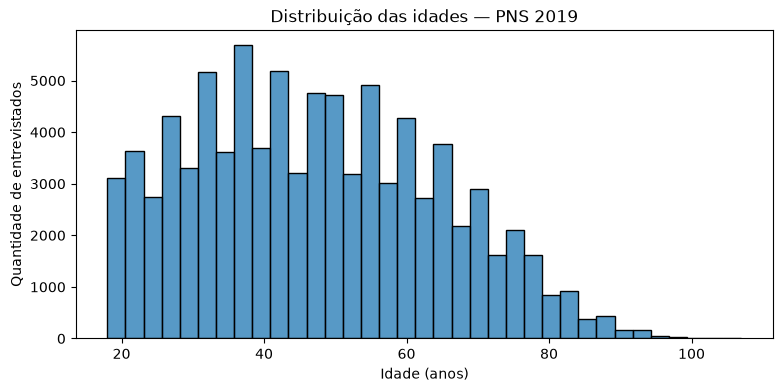

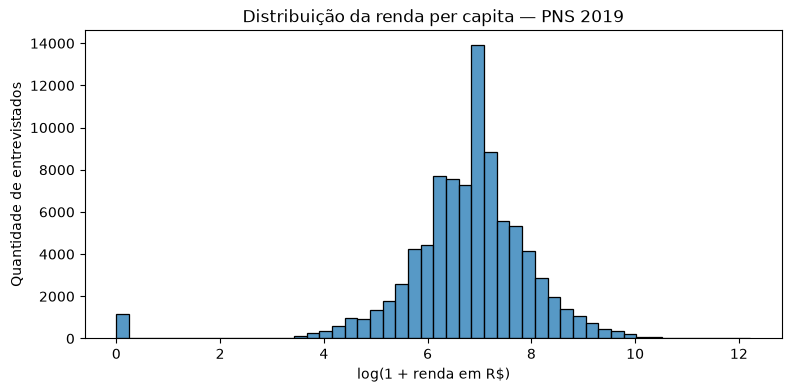

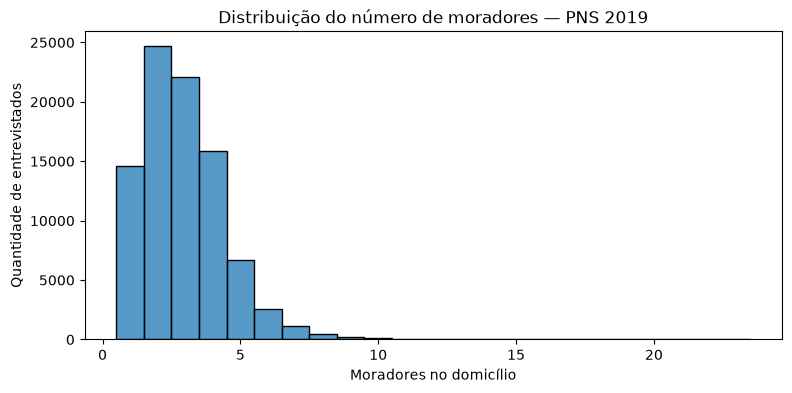

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns

# Gráfico 1: Idade
plt.figure(figsize=(9, 4))
sns.histplot(df_eda["idade"], bins=35)
plt.title("Distribuição das idades — PNS 2019")
plt.xlabel("Idade (anos)")
plt.ylabel("Quantidade de entrevistados")
plt.show()

# Gráfico 2: Renda em escala logarítmica
plt.figure(figsize=(9, 4))
sns.histplot(np.log1p(df_eda["renda_per_capita"]), bins=50)
plt.title("Distribuição da renda per capita — PNS 2019")
plt.xlabel("log(1 + renda em R$)")
plt.ylabel("Quantidade de entrevistados")
plt.show()

# Gráfico 3: Número de moradores
plt.figure(figsize=(9, 4))
sns.histplot(df_eda["numero_moradores"], discrete=True)
plt.title("Distribuição do número de moradores — PNS 2019")
plt.xlabel("Moradores no domicílio")
plt.ylabel("Quantidade de entrevistados")
plt.show()


In [52]:
# Criar grupos de idade
df_eda["faixa_idade"] = pd.cut(
    df_eda["idade"],
    bins=[18, 30, 45, 60, 75, 108],
    right=False,
    labels=["18-29", "30-44", "45-59", "60-74", "75+"],
)

# Criar grupos de renda por quartis
df_eda["faixa_renda"] = pd.qcut(
    df_eda["renda_per_capita"], q=4, duplicates="drop"
)

# Criar grupos de moradores
df_eda["faixa_moradores"] = pd.cut(
    df_eda["numero_moradores"],
    bins=[0, 1, 2, 4, np.inf],
    labels=["1", "2", "3-4", "5+"],
)


In [53]:
def analisar_atividade(df, coluna):

    resultado = df.groupby(coluna, observed=True, dropna=False).agg(
        entrevistados=("ativo_lazer", "size"),
        ativos=("ativo_lazer", "sum"),
        percentual_ativos=("ativo_lazer", "mean"),
    )

    resultado["percentual_ativos"] = (
        resultado["percentual_ativos"] * 100
    ).round(2)

    return resultado


In [54]:
variaveis_eda = [
    "faixa_idade",
    "sexo",
    "escolaridade",
    "faixa_renda",
    "uf",
    "situacao_trabalho",
    "area_residencia",
    "raca_cor",
    "estado_civil",
    "faixa_moradores",
]

resultados_bivariados = {}

for coluna in variaveis_eda:

    resultado = analisar_atividade(df_eda, coluna)
    resultados_bivariados[coluna] = resultado

    print(f"\n{'=' * 45}")
    print(f"Atividade física por {coluna}")
    print("=" * 45)

    display(resultado)



Atividade física por faixa_idade


,entrevistados,ativos,percentual_ativos
faixa_idade,,,
18-29,15377,6058,39.4
30-44,26728,8705,32.57
45-59,23637,6046,25.58
60-74,16755,3558,21.24
75+,5959,698,11.71



Atividade física por sexo


,entrevistados,ativos,percentual_ativos
sexo,,,
Homem,41622,12825,30.81
Mulher,46834,12240,26.13



Atividade física por escolaridade


...

,entrevistados,ativos,percentual_ativos
raca_cor,,,
Amarela,665,223,33.53
Branca,32387,9719,30.01
Indígena,669,169,25.26
Parda,44612,12091,27.1
Preta,10123,2863,28.28



Atividade física por estado_civil


,entrevistados,ativos,percentual_ativos
estado_civil,,,
Casado(a),35090,9699,27.64
Divorciado(a) ou separado(a),7507,2248,29.95
Solteiro(a),38235,11795,30.85
Viúvo(a),7624,1323,17.35



Atividade física por faixa_moradores


,entrevistados,ativos,percentual_ativos
faixa_moradores,,,
1,14636,4042,27.62
2,24685,6698,27.13
3-4,37952,11316,29.82
5+,11183,3009,26.91


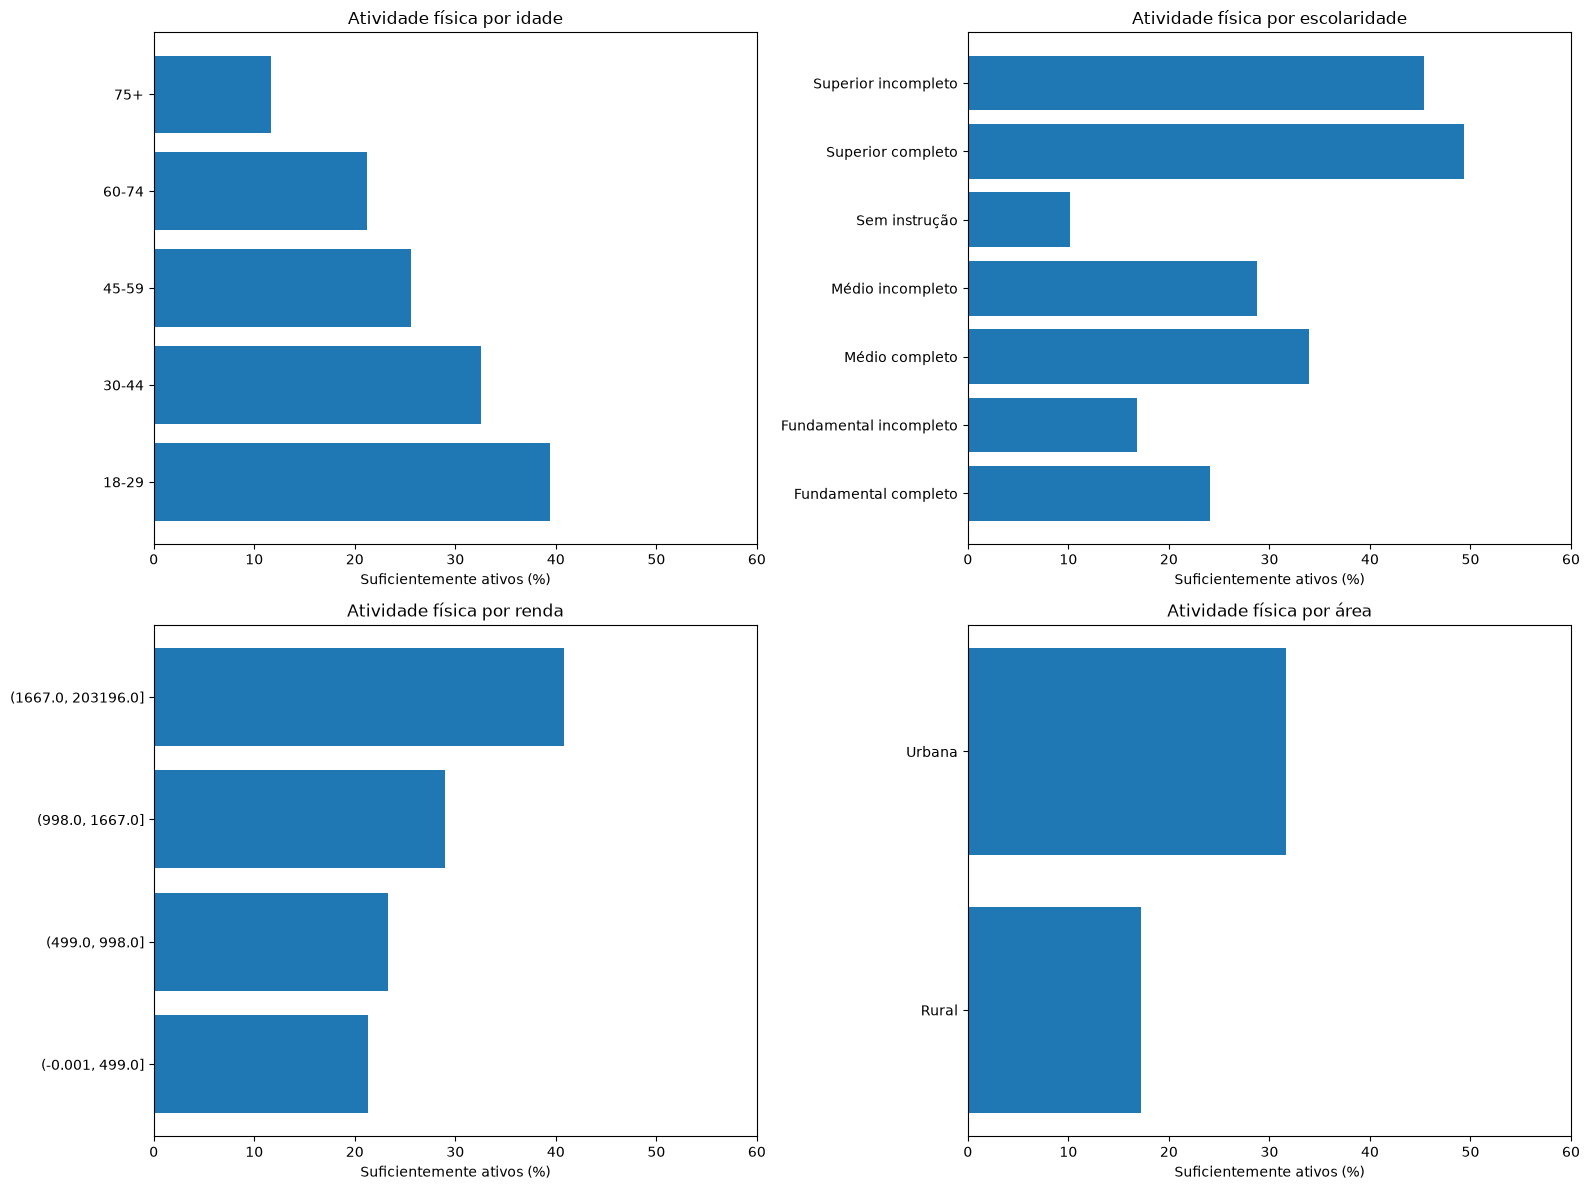

In [55]:
variaveis_grafico = {
    "faixa_idade": "Atividade física por idade",
    "escolaridade": "Atividade física por escolaridade",
    "faixa_renda": "Atividade física por renda",
    "area_residencia": "Atividade física por área",
}

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for ax, (coluna, titulo) in zip(axes.flat, variaveis_grafico.items()):
    tabela = resultados_bivariados[coluna].copy()

    ax.barh(tabela.index.astype(str), tabela["percentual_ativos"])

    ax.set_title(titulo)
    ax.set_xlabel("Suficientemente ativos (%)")
    ax.set_xlim(0, 60)

plt.tight_layout()
plt.show()


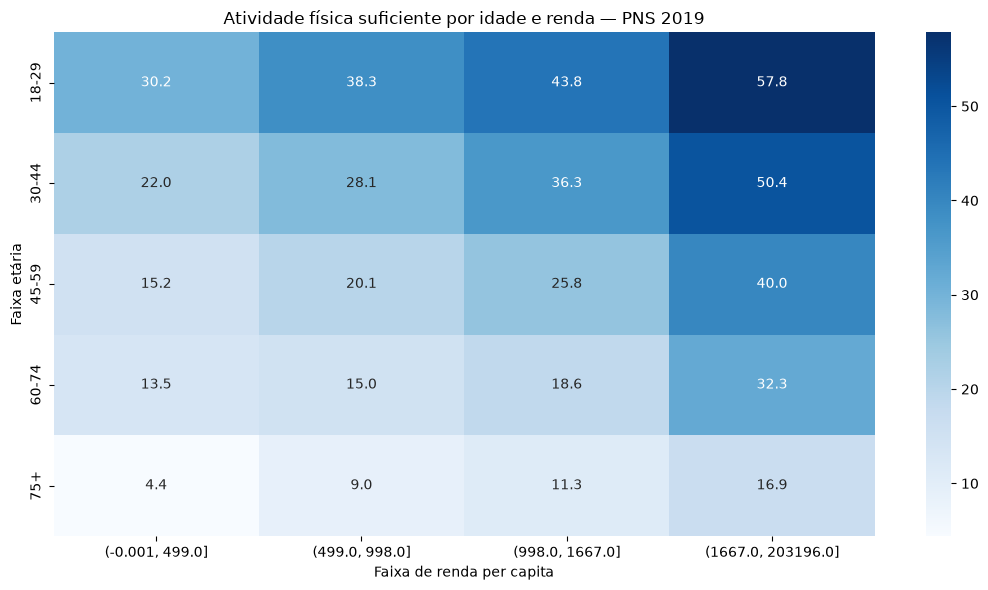

In [56]:
# Calcular percentual de ativos em cada combinação
matriz = (
    df_eda.groupby(["faixa_idade", "faixa_renda"], observed=True)[
        "ativo_lazer"
    ]
    .mean()
    .unstack()
    * 100
)

plt.figure(figsize=(11, 6))

sns.heatmap(matriz.astype(float), annot=True, fmt=".1f", cmap="Blues")

plt.title("Atividade física suficiente por idade e renda — PNS 2019")

plt.xlabel("Faixa de renda per capita")
plt.ylabel("Faixa etária")
plt.tight_layout()
plt.show()


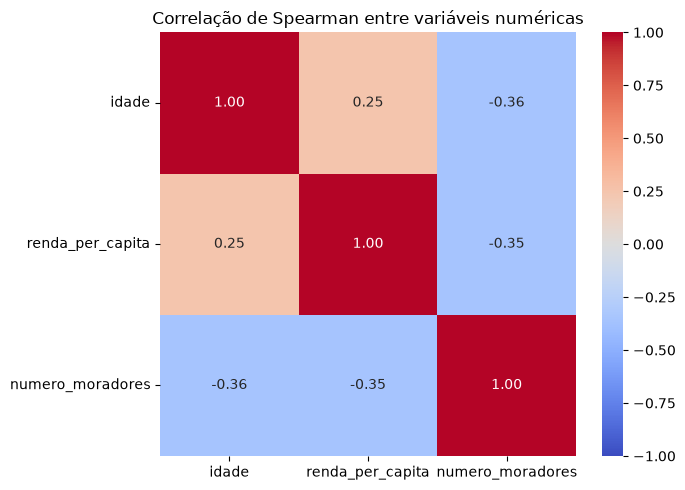

In [57]:
numericas = ["idade", "renda_per_capita", "numero_moradores"]

# Correlação de Spearman
correlacoes = df_eda[numericas].corr(method="spearman")

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlacoes, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1
)

plt.title("Correlação de Spearman entre variáveis numéricas")
plt.tight_layout()
plt.show()


In [58]:
from scipy.stats import chi2_contingency

# Variáveis categóricas da nossa PNS
categoricas = [
    "sexo",
    "escolaridade",
    "situacao_trabalho",
    "area_residencia",
    "raca_cor",
    "estado_civil",
    "uf",
]


# Função para calcular V de Cramér
# com correção de viés
def cramers_v(x, y):
    tabela = pd.crosstab(x, y)

    n = tabela.to_numpy().sum()
    r, k = tabela.shape

    if n <= 1 or min(r, k) < 2:
        return np.nan

    chi2 = chi2_contingency(tabela, correction=False)[0]

    phi2 = chi2 / n

    phi2_corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))

    r_corr = r - ((r - 1) ** 2) / (n - 1)
    k_corr = k - ((k - 1) ** 2) / (n - 1)

    denominador = min(r_corr - 1, k_corr - 1)

    if denominador <= 0:
        return np.nan

    return np.sqrt(phi2_corr / denominador)


# Matriz de associações
matriz_cramer = pd.DataFrame(
    index=categoricas, columns=categoricas, dtype=float
)

for x in categoricas:
    for y in categoricas:
        if x == y:
            matriz_cramer.loc[x, y] = 1.0
        else:
            matriz_cramer.loc[x, y] = cramers_v(df_eda[x], df_eda[y])

display(matriz_cramer.round(3))


,sexo,escolaridade,situacao_trabalho,area_residencia,raca_cor,estado_civil,uf
sexo,1.000,0.070,0.232,0.100,0.012,0.195,0.033
escolaridade,0.070,1.000,0.220,0.316,0.096,0.142,0.097
situacao_trabalho,0.232,0.220,1.000,0.076,0.029,0.203,0.084
area_residencia,0.100,0.316,0.076,1.000,0.097,0.077,0.226
raca_cor,0.012,0.096,0.029,0.097,1.000,0.070,0.219
estado_civil,0.195,0.142,0.203,0.077,0.070,1.000,0.104
uf,0.033,0.097,0.084,0.226,0.219,0.104,1.000


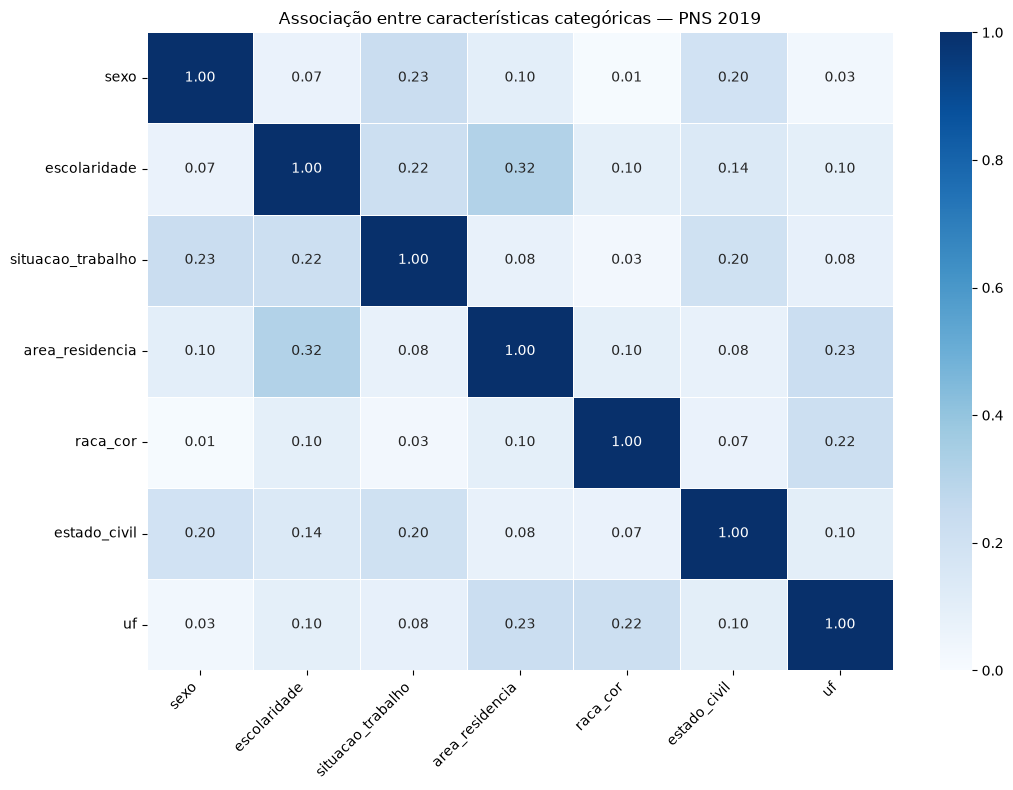

In [59]:
plt.figure(figsize=(11, 8))

sns.heatmap(
    matriz_cramer,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    linewidths=0.5,
)

plt.title("Associação entre características categóricas — PNS 2019")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


In [60]:
from itertools import combinations

associacoes = []

for var1, var2 in combinations(categoricas, 2):
    associacoes.append(
        {
            "Variável 1": var1,
            "Variável 2": var2,
            "V de Cramér": matriz_cramer.loc[var1, var2],
        }
    )

resultado_associacoes = pd.DataFrame(associacoes)

resultado_associacoes = resultado_associacoes.sort_values(
    "V de Cramér", ascending=False
)

display(resultado_associacoes.head(10))


,Variável 1,Variável 2,V de Cramér
7,escolaridade,area_residencia,0.316022
1,sexo,situacao_trabalho,0.231907
17,area_residencia,uf,0.225636
6,escolaridade,situacao_trabalho,0.219738
19,raca_cor,uf,0.219411
13,situacao_trabalho,estado_civil,0.203184
4,sexo,estado_civil,0.195275
9,escolaridade,estado_civil,0.142010
20,estado_civil,uf,0.104143
2,sexo,area_residencia,0.099727


In [61]:
associacoes = []

for var1, var2 in combinations(categoricas, 2):
    associacoes.append(
        {
            "Variável 1": var1,
            "Variável 2": var2,
            "V de Cramér": matriz_cramer.loc[var1, var2],
        }
    )

resultado_associacoes = pd.DataFrame(associacoes)

resultado_associacoes = resultado_associacoes.sort_values(
    "V de Cramér", ascending=False
)

display(resultado_associacoes.head(10))


,Variável 1,Variável 2,V de Cramér
7,escolaridade,area_residencia,0.316022
1,sexo,situacao_trabalho,0.231907
17,area_residencia,uf,0.225636
6,escolaridade,situacao_trabalho,0.219738
19,raca_cor,uf,0.219411
13,situacao_trabalho,estado_civil,0.203184
4,sexo,estado_civil,0.195275
9,escolaridade,estado_civil,0.142010
20,estado_civil,uf,0.104143
2,sexo,area_residencia,0.099727


In [62]:
# Colunas necessárias para nossa EDA
colunas_eda = [
    "idade",
    "sexo",
    "escolaridade",
    "renda_per_capita",
    "uf",
    "situacao_trabalho",
    "area_residencia",
    "raca_cor",
    "estado_civil",
    "numero_moradores",
    "ativo_lazer",
]

# Criar cópia independente
base_eda = df_final[colunas_eda].copy()

# Corrigir os tipos numéricos
for coluna in ["idade", "renda_per_capita", "numero_moradores"]:
    base_eda[coluna] = pd.to_numeric(base_eda[coluna], errors="coerce")

base_eda["ativo_lazer"] = pd.to_numeric(
    base_eda["ativo_lazer"], errors="coerce"
).astype("Int64")

# Conferir a base
print("Dimensões:", base_eda.shape)
print("Ausentes:", base_eda.isna().sum().sum())

assert base_eda.isna().sum().sum() == 0
assert base_eda["ativo_lazer"].isin([0, 1]).all()

# Salvar a base para análise exploratória
INTERIM.mkdir(parents=True, exist_ok=True)

base_eda.to_parquet(INTERIM / "pns_base_eda.parquet", index=False)

print("Base para EDA salva com sucesso!")


Dimensões: (88456, 11)
Ausentes: 0
Base para EDA salva com sucesso!
